In [8]:
# REQUIRES, IMPORTS, ETC.
# =======================
# System
# ------
import time

# Third-party libraries
# ----------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# MODULES
# ========
# System
# --------------
from pathlib import Path
from typing import Dict

# Custom
# Defines
# -------
from src.config.globals import *

# Helpers functions
# -----------------
import src.helpers.validations as val
import src.helpers.console as csl
import src.helpers.charts as cht

In [9]:
# CHECK CHANGES ONF IMPORT FILES
# ==============================
import importlib
importlib.reload(csl)
importlib.reload(cht)
importlib.reload(val)

print(csl.__file__)
print([name for name in dir(csl)])
print("+ ")

print(cht.__file__)
print([name for name in dir(cht)])
print("+ ")

print(val.__file__)
print([name for name in dir(val)])

/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/console.py
['LineBreak', 'SectionBegin', 'SectionBreak', 'SectionEnd', 'SectionErrEndAndExit', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'nbsp', 'sys', 'time']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/charts.py
['BarCht', 'ChartType', 'Dict', 'DifferenceCht', 'DuplicatedCht', 'HistogramCht', 'LineCht', 'PlotSalesAnalytics', 'QualityCht', 'RelationalScatterCht', 'ResidualsScatterCht', 'ScatterCht', 'SequentialScatterCht', 'StripCht', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'pd', 'plt', 'sns', 'sys', 'val']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/validations.py
['Dict', 'ValidateParams', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__

In [10]:
# GLOBAL VARIABLES, PATHS
# =======================
# Current file paths
# ------------------
NOTEBOOK_DIR = Path.cwd()
DATA_DIR = (NOTEBOOK_DIR.parent / "data").resolve()

# Global variables definition for this notebook
# ---------------------------------------------
dataset: str = DATA_DIR / "iris.csv"

# Pandas dataframe to hold the dataset
df: pd.DataFrame
# Algorithm result
res: dict[str, any]
# Kind of sepals
sepalFeatures: dict[str] = [
  "sepal_length",
  "sepal_width",
  "petal_length",
  "petal_width"
]

In [11]:
# DATA ANALYSIS IRIS, 1. LOAD SOURCE DATASET (from CSV file)
# ==========================================================
csl.SectionBegin(f"DATA ANALYSIS IRIS, 1. LOAD SOURCE DATASET (from CSV file)\nDATASET PATH: \n{dataset}", 0)
csl.SectionBreak(0, 0)

try:
  df = pd.read_csv(dataset)
  print(f"File loaded successfully. Total of original rows: {len(df)}")
  print(f"First 5 rows of the dataset:")
  print(df.head())
  
except FileNotFoundError:
  print(f"Error: Please, check path. \n'{dataset}'")
  print(f"Error: File not found.")

csl.SectionEnd(0)


+ =========================================================
+ DATA ANALYSIS IRIS, 1. LOAD SOURCE DATASET (from CSV file)
DATASET PATH: 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/activities/RA2/lesson_03/data/iris.csv
+ ---------------------------------------------------------
File loaded successfully. Total of original rows: 150
First 5 rows of the dataset:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
+ =========================================================


+ =========================================================
+ DATA ANALYSIS IRIS, 2. MULTIVAR HISTOGRAM
+ ---------------------------------------------------------


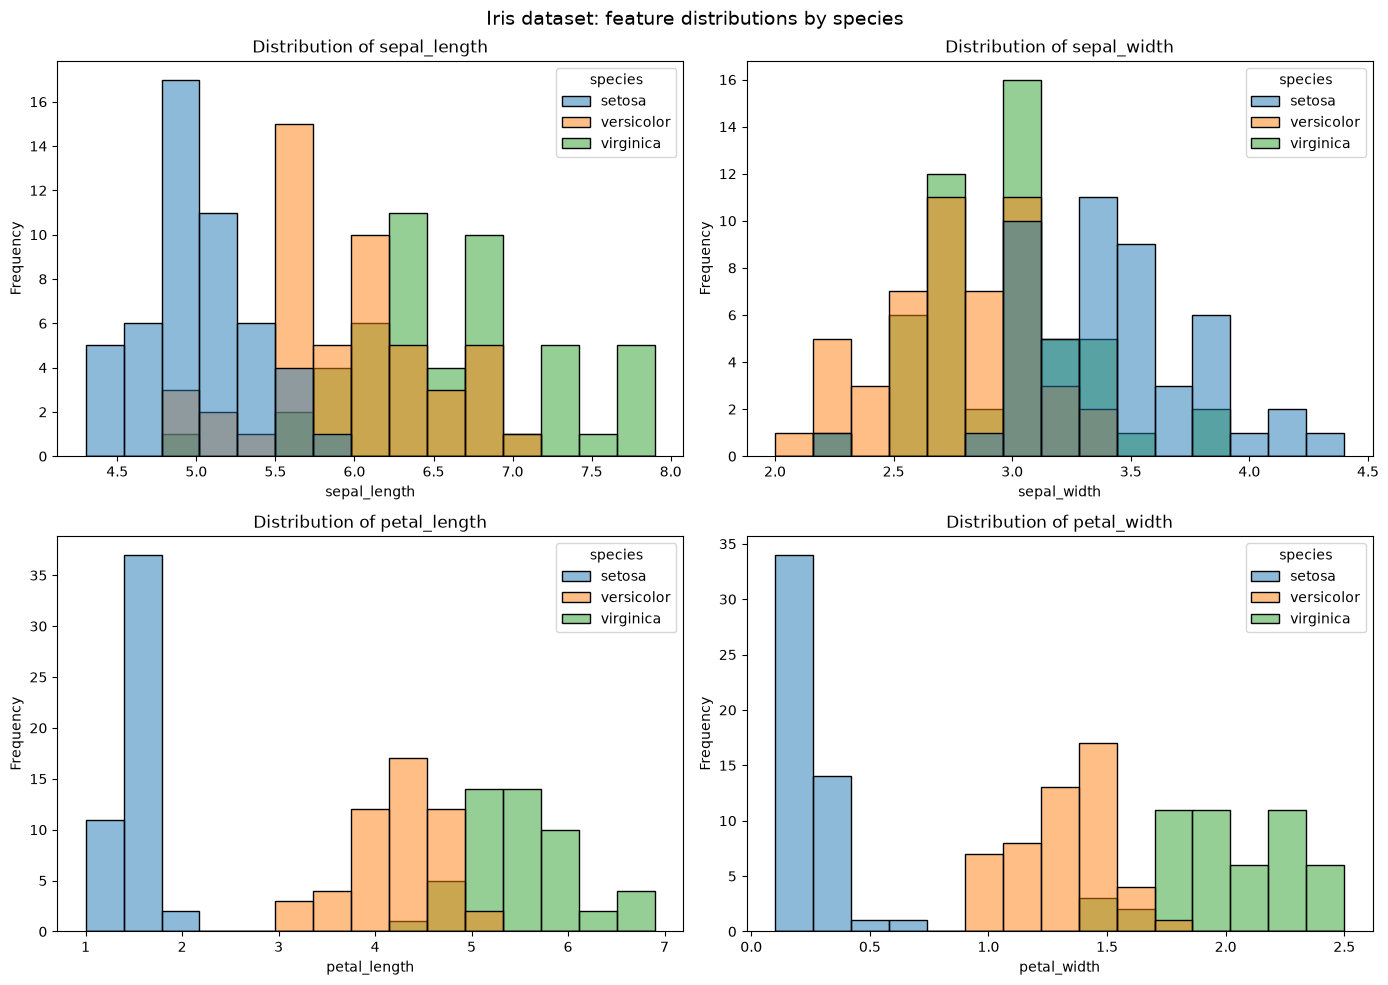

+ ---------------------------------------------------------
+ Time to load: 1.2979 seconds
+ =========================================================


In [ ]:
# DATA ANALYSIS IRIS, 2. MULTIVAR HISTOGRAM
# =========================================
tInit: float = time.time()

# MultivarHistogram
# -----------------
# Show the multivariable histogram plot by species
# 
# @param pDf: pd.DataFrame The pandas dataframe.
# @return None
def MultivarHistogram(pDf: pd.DataFrame) -> list[dict]:
  fig, axes = plt.subplots(2, 2, figsize=(14, 10))

  for feature, ax in zip(sepalFeatures, axes.flatten()):
    sns.histplot(
      data=pDf,
      x=feature,
      hue="species",
      bins=15,
      multiple="layer",
      alpha=0.5,
      ax=ax
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")

  fig.suptitle("Iris dataset: feature distributions by species", fontsize=14)
  plt.tight_layout()
  plt.show()
  
  return {'bOk': True}

# Execute script
csl.SectionBegin("DATA ANALYSIS IRIS, 2. MULTIVAR HISTOGRAM", 0)
csl.SectionBreak(0,0)

res = MultivarHistogram(df)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA ANALYSIS IRIS, 3. PAIRPLOT WITH RELATIONSHIPS BETWEEN FEATURES
+ ---------------------------------------------------------


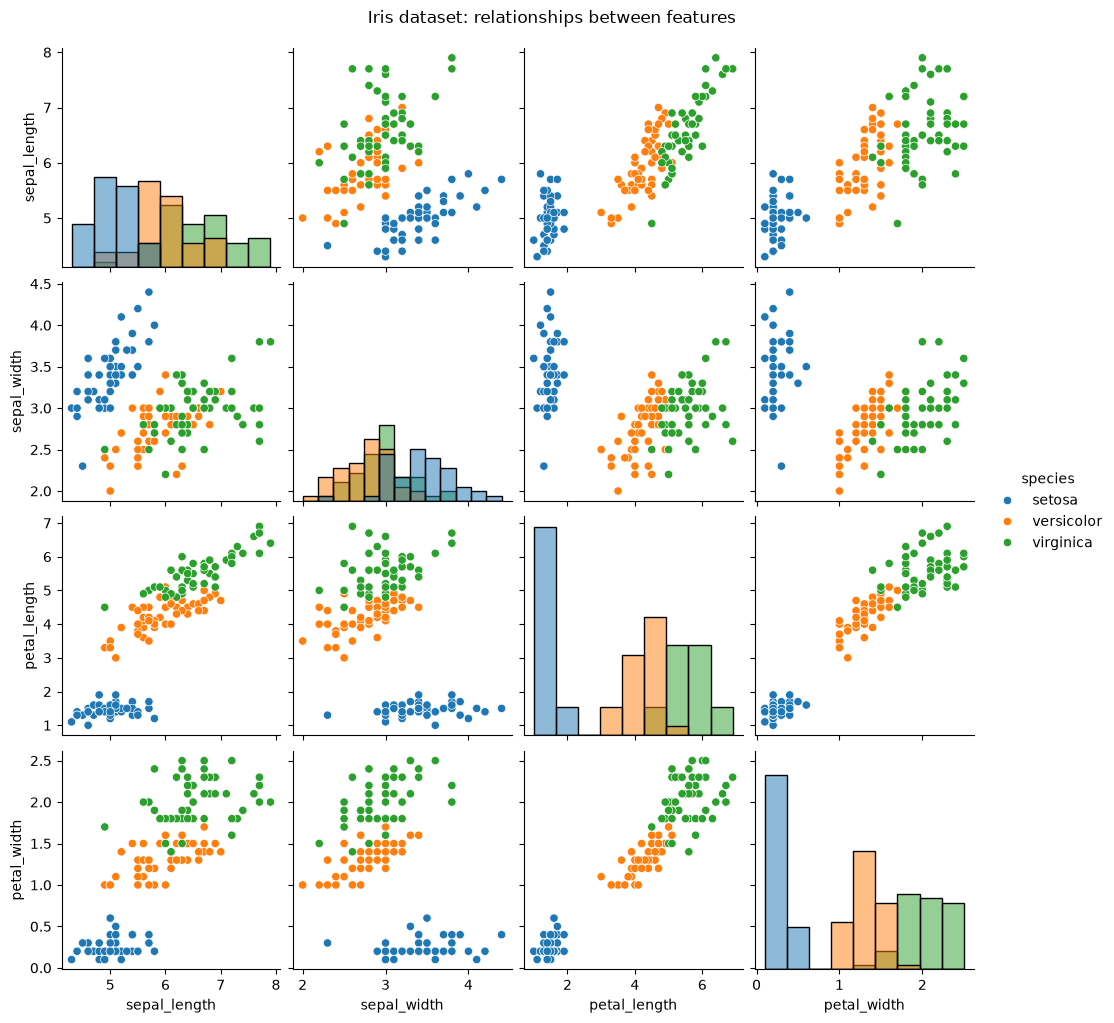

+ ---------------------------------------------------------
+ Time to load: 2.9100 seconds
+ =========================================================


In [ ]:
# DATA ANALYSIS IRIS, 3. PAIRPLOT WITH RELATIONSHIPS BETWEEN FEATURES
# ===================================================================
tInit: float = time.time()

# PairPlot
# --------
# Show the plot with relationships between features 
# 
# @param pDf: pd.DataFrame The pandas dataframe
# @return None
def PairPlot(pDf: pd.DataFrame) -> list[dict]:
  sns.pairplot(
    data=pDf,
    vars=sepalFeatures,
    hue="species",
    diag_kind="hist"
  ).figure.suptitle("Iris dataset: relationships between features", y=1.02)
  
  plt.show()
  
  return {'bOk': True}

# Execute script
csl.SectionBegin("DATA ANALYSIS IRIS, 3. PAIRPLOT WITH RELATIONSHIPS BETWEEN FEATURES", 0)
csl.SectionBreak(0,0)

res = PairPlot(df)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA ANALYSIS IRIS, 4. CORRELATION HEATMAP
+ ---------------------------------------------------------


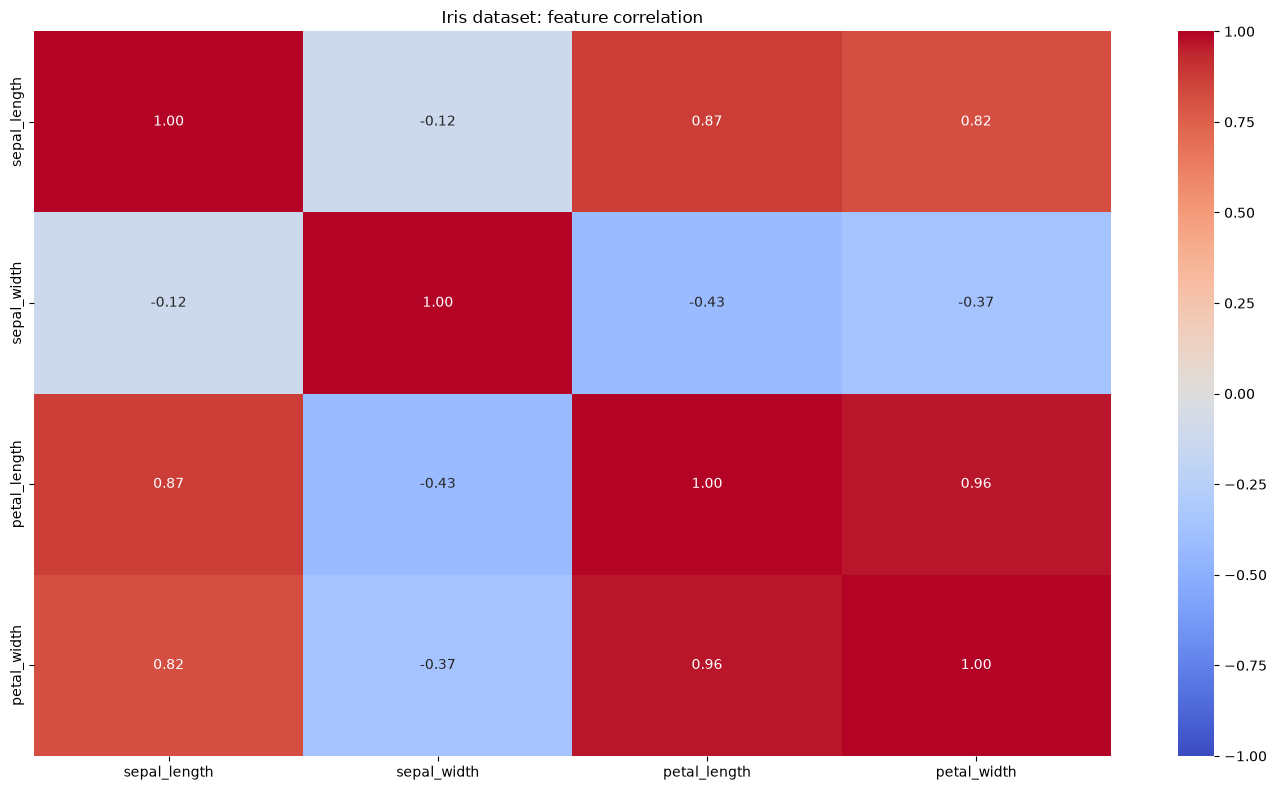

+ ---------------------------------------------------------
+ Time to load: 0.3740 seconds
+ =========================================================


In [ ]:
# DATA ANALYSIS IRIS, 4. CORRELATION HEATMAP
# ==========================================
tInit: float = time.time()

# CorrelationHeatmap
# ------------------
# Show the heatmap plot with correlations between features 
# 
# @param pDf: pd.DataFrame The pandas dataframe
# @return None
def CorrelationHeatmap(pDf: pd.DataFrame) -> list[dict]:
  correlation: pd.DataFrame = pDf[sepalFeatures].corr()

  fig, ax = plt.subplots(figsize=(14, 8))

  sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    ax=ax
  )

  ax.set_title("Iris dataset: feature correlation")

  plt.tight_layout()
  plt.show()
  
  return {'bOk': True}

# Execute script
csl.SectionBegin("DATA ANALYSIS IRIS, 4. CORRELATION HEATMAP", 0)
csl.SectionBreak(0,0)

res = CorrelationHeatmap(df)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ DATA ANALYSIS IRIS, 5. VIOLIN PLOTS OF FEATURES BY SPECIES
+ ---------------------------------------------------------


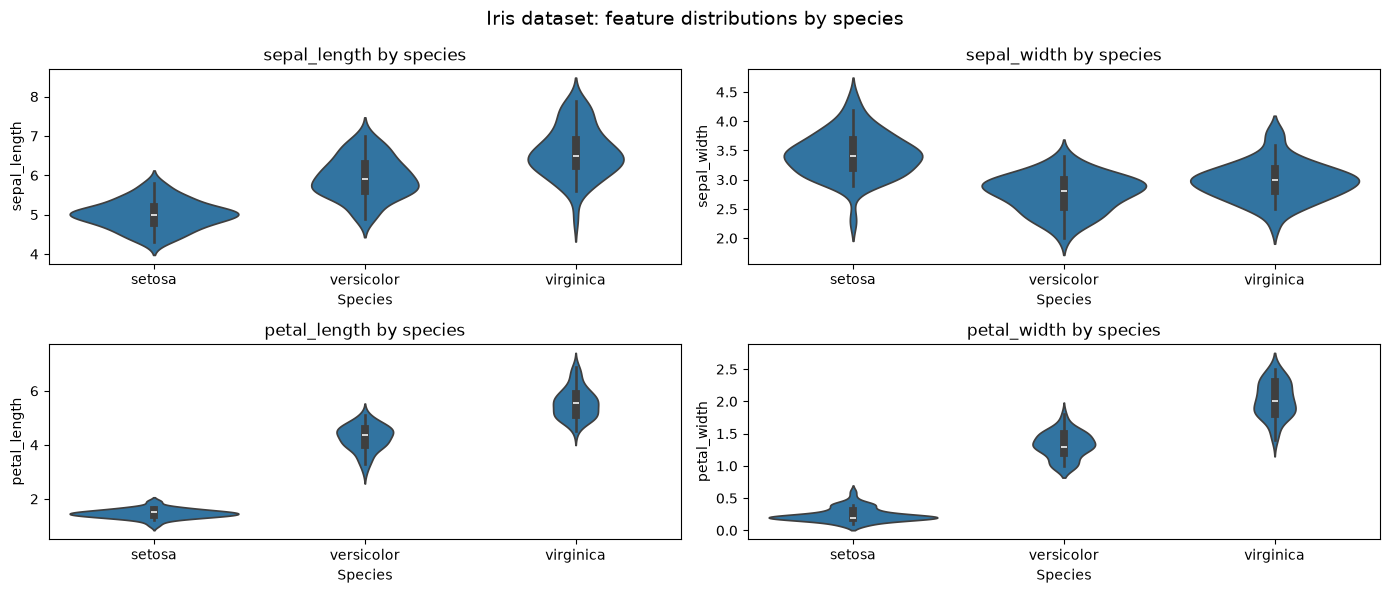

+ ---------------------------------------------------------
+ Time to load: 0.7467 seconds
+ =========================================================


In [23]:
# DATA ANALYSIS IRIS, 5. VIOLIN PLOTS OF FEATURES BY SPECIES
# ==========================================================
tInit: float = time.time()

# ViolinplotBySpecies
# -------------------
# Show the plot with relationships between features 
# 
# @param pDf: pd.DataFrame The pandas dataframe
# @return None
def ViolinplotBySpecies(pDf: pd.DataFrame) -> list[dict]:
  fig, axes = plt.subplots(2, 2, figsize=(14, 6))

  for feature, ax in zip(sepalFeatures, axes.flatten()):
    sns.violinplot(
      data=df,
      x="species",
      y=feature,
      ax=ax
    )

    ax.set_title(f"{feature} by species")
    ax.set_xlabel("Species")
    ax.set_ylabel(feature)

  fig.suptitle("Iris dataset: feature distributions by species", fontsize=14)

  plt.tight_layout()
  plt.show()
  
  return {'bOk': True}

# Execute script
csl.SectionBegin("DATA ANALYSIS IRIS, 5. VIOLIN PLOTS OF FEATURES BY SPECIES", 0)
csl.SectionBreak(0,0)

res = ViolinplotBySpecies(df)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)